# 2D Advection–Diffusion

# Problem

$$\partial_t c + u \partial_x c = D \partial_{xx} c$$


With the following boundary conditions, only one is needed

\begin{align}
    C(x,0) &= \delta(x) \\
    C(\pm L, t) &= 0 \\
\end{align}

$$c_m^0 = \frac{1}{\Delta x}\,\delta_{m,0}$$

so that for M0, our initial mass
$$\sum_m c_m^0\,\Delta x = M_0$$

---
# Central Differance
Central differences in space and forward Euler in time, with $c_m^n \approx c(m\,\Delta x,\; n\,\Delta t)$:

$$c_m^{n+1} = (a+b)\,c_{m-1}^n + (1-2b)\,c_m^n + (b-a)\,c_{m+1}^n$$

where

$$a = \frac{u\,\Delta t}{2\,\Delta x}, \qquad b = \frac{D\,\Delta t}{\Delta x^2}$$

Stability requires $b \le \tfrac{1}{2}$ and $2a^2 \le b$. To avoid oscillations, also require $a \le b$. The three coefficients of $c_m^n$ must sum to one 

---

# u and D can be functions
*with some tighter restrictions*

We still require  $b \le \tfrac{1}{2}$ and $a \le b$ and from these conditions respecitvely 

$$\Delta t \le \frac{\Delta x^2}{2\max D}, \qquad \Delta x \le \frac{2\min D}{\max|u|}$$


In [100]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import HTML, display
import imageio_ffmpeg
import matplotlib as mpl
from scipy import sparse as sp


In [101]:
def I_1(x, y, M, delta_x, delta_y, nx, ny):
    C0 = np.zeros((nx+1, ny+1))
    C0[len(x) // 2, len(y)//2] = M / (delta_x*delta_y)     # at x==0
    
    return C0


In [102]:
def solve_forward_2D(D, U, T, Nt, dx, dy, xy0):
    """
    Solve a 2D advection-diffusion step forward in time on an (nx, ny) grid.

    INPUTS:
    D   : diffusion coefficient
    U   : constant advection velocity
    T   : total simulation time
    Nt  : number of time steps
    dx  : grid spacing in x
    dy  : grid spacing in y
    xy0 : 2D initial condition array of shape (nx, ny)

    OUTPUTS:
    c   : solution array of shape (Nt + 1, nx, ny), or None if unstable
    """
    if xy0 is None:
        raise ValueError("xy0 must be a 2D numpy array of initial conditions, not None. This could be a result of a previous simulation...")

    xy0 = np.asarray(xy0, dtype=float)
    nx, ny = xy0.shape
    dt = T / Nt

    ax = D * dt / (dx ** 2)
    ay = D * dt / (dy ** 2)
    bx = U * dt / (2.0 * dx)
    by = U * dt / (2.0 * dy)

    # Explicit stability checks (diffusion CFL + central-difference advection bound)
    if ax > 0.5 or ay > 0.5 or (bx ** 2) > ax or (by ** 2) > ay:
        print(f"UNSTABLE: ax={ax:.4g}, ay={ay:.4g}, bx={bx:.4g}, by={by:.4g}")
        return None

    # deal with x and y seperatelt, these are still stored in c[k] as (x,y) arrays for all timesteps in 
    # 1D operators for x (size nx) and y (size ny)
    # Using central difference for advection + 2nd-order central difference for diffusion
    #
    #
    Lx = sp.diags(
        [ax + bx, -2.0 * ax, ax - bx],
        offsets=[-1, 0, 1],
        shape=(nx, nx),
        format="csr",
    )
    Ly = sp.diags(
        [ay + by, -2.0 * ay, ay - by],
        offsets=[-1, 0, 1],
        shape=(ny, ny),
        format="csr",
    )

    Ix = sp.eye(nx, format="csr")
    Iy = sp.eye(ny, format="csr")

    # 2D transition matrix on flattened state of length nx * ny: c_{n+1} = A @ c_n
    A = sp.eye(nx * ny, format="csr") + sp.kron(Lx, Iy, format="csr") + sp.kron(Ix, Ly, format="csr")

    c = np.zeros((Nt + 1, nx, ny), dtype=float)
    c[0] = xy0

    state = xy0.ravel().copy()
    for i in range(Nt):
        state = A @ state
        #the reshape changes it to a 2D array of shape (nx, ny) for the BC implementation
        state = state.reshape((nx, ny))
        #BC's
        state[0, :] = 0.0
        state[-1, :] = 0.0
        state[:, 0] = 0.0
        state[:, -1] = 0.0

        c[i + 1] = state
        state = state.ravel()   
        # flatten it again for the next A @ state

    return c

In [103]:

#plots solution at given time step k
def plot3D(t, x, y, c, k, frame):
    x_mask = (x >= frame[0]) & (x <= frame[1])
    y_mask = (y >= frame[2]) & (y <= frame[3])
    x_view = x[x_mask]
    y_view = y[y_mask]
    if x_view.size == 0 or y_view.size == 0:
        raise ValueError("frame must overlap the x and y coordinate ranges")

    X, Y = np.meshgrid(x_view, y_view, indexing="ij")
    Z = c[k][np.ix_(x_mask, y_mask)]

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection = "3d")

    ax.plot_surface(X, Y, Z, cmap = "viridis")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("c(x, y, t)")
    ax.set_title(f'Numerical solution at t = {t[k]}')
    ax.set_xlim(frame[0], frame[1])
    ax.set_ylim(frame[2], frame[3])

    plt.show()

#plots initial, midpoint, and final concentration fields side by side
def plot_snapshots(c, x, y, T, frame):
    """
    Plot initial, midpoint, and final concentration fields side by side.
    frame is [xmin, xmax, ymin, ymax] for the plot limits
    """
    indices = [0, len(c) // 2, len(c) - 1]
    times = np.linspace(0.0, T, len(c))
    vmin, vmax = c.min(), c.max()

    fig, axes = plt.subplots(1, len(indices), figsize=(14, 4), constrained_layout=True)
    for ax_plot, idx in zip(axes, indices):
        # transpose so x is horizontal and y is vertical
        im = ax_plot.pcolormesh(x, y, c[idx].T, shading="auto", vmin=vmin, vmax=vmax, cmap="viridis")
        ax_plot.set_title(f"t = {times[idx]:.2f}")
        ax_plot.set_xlabel("x")
        ax_plot.set_ylabel("y")

        ax_plot.set_xlim(frame[0], frame[1])
        ax_plot.set_ylim(frame[2], frame[3])
        ax_plot.set_aspect("equal")

    fig.colorbar(im, ax=axes, label="Concentration c")
    plt.show()
def find_frame(x,y):
    """
        Return [xmin, xmax, ymin, ymax] covering the central fifth of the domain.
    """
    xmid = (x[0] + x[-1]) / 2.0
    ymid = (y[0] + y[-1]) / 2.0
    xhalf = (x[-1] - x[0]) / 10.0
    yhalf = (y[-1] - y[0]) / 10.0
    return [xmid - xhalf, xmid + xhalf, ymid - yhalf, ymid + yhalf]
   

In [ ]:
#generates moving animation for a given solution set
def animate_solution(c, x, y, T, frame, interval_ms=100, frame_skip=10):
    """
        Optional: animate the concentration evolution over time.
        x : 1D array of x-coordinates for the grid
        y : 1D array of y-coordinates
        T : total simulation time
        frame : [xmin, xmax, ymin, ymax] plot limits
        interval_ms : time between frames in milliseconds
        frame_skip : number of solution frames to skip between displayed frames

        changing interval_ms will change the speed of the animation, 
        changinh the number of frames will change the smoothness of the animation & rendering time.
    """
    #we have to mask the points for 3d or the surface plot spills out
    times = np.linspace(0.0, T, len(c))
    vmin, vmax = c.min(), c.max()

    fig, ax_plot = plt.subplots(figsize=(5.5, 4.5))
    quad = ax_plot.pcolormesh(x, y, c[0].T, shading="auto", vmin=vmin, vmax=vmax, cmap="viridis")
    cbar = fig.colorbar(quad, ax=ax_plot, label="Concentration c")
    title = ax_plot.set_title(f"t = {times[0]:.2f}")
    ax_plot.set_xlabel("x")
    ax_plot.set_ylabel("y")
    ax_plot.set_aspect("equal")
    ax_plot.set_xlim(frame[0], frame[1])
    ax_plot.set_ylim(frame[2], frame[3])

    def update(frame_idx):
        quad.set_array(c[frame_idx].T.ravel())
        title.set_text(f"t = {times[frame_idx]:.2f}")
        return quad, title

    anim = FuncAnimation(
        fig, update,
        frames=range(0, len(c), frame_skip),
        interval=interval_ms,
        blit=False
    )
    plt.close(fig)  # Prevents duplicate static plot in Jupyter notebooks
    return anim

In [ ]:
def animate_3D(c, x, y, T, frame, interval_ms=100, frame_skip=10):
    """Animate the concentration surface over time within frame."""

    #we have to mask the points for 3d or the surface plot spills out
    x_mask = (x >= frame[0]) & (x <= frame[1])
    y_mask = (y >= frame[2]) & (y <= frame[3])
    x_view = x[x_mask]
    y_view = y[y_mask]
    if x_view.size == 0 or y_view.size == 0:
        raise ValueError("frame must overlap the x and y coordinate ranges")

    X, Y = np.meshgrid(x_view, y_view, indexing="ij")
    Z = c[:, x_mask, :][:, :, y_mask]
    times = np.linspace(0.0, T, len(c))
    z_min = min(0.0, float(Z.min()))
    z_max = float(Z.max())
    if z_min == z_max:
        z_max = z_min + 1.0

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("c(x, y, t)")
    ax.set_xlim(frame[0], frame[1])
    ax.set_ylim(frame[2], frame[3])
    ax.set_zlim(z_min, z_max)
    ax.set_title(f"Concentration at t = {times[0]:.2f}")

    surface = [ax.plot_surface(X, Y, Z[0], cmap="viridis", vmin=z_min, vmax=z_max)]

    def update(frame_idx):
        surface[0].remove()
        surface[0] = ax.plot_surface(
            X, Y, Z[frame_idx], cmap="viridis", vmin=z_min, vmax=z_max
        )
        ax.set_title(f"Concentration at t = {times[frame_idx]:.2f}")
        return (surface[0],)

    frame_indices = list(range(0, len(c), frame_skip))
    if frame_indices[-1] != len(c) - 1:
        frame_indices.append(len(c) - 1)
    anim = FuncAnimation(
        fig, update, frames=frame_indices, interval=interval_ms, blit=False
    )
    plt.close(fig)
    return anim

In [106]:

def test():
    D = 0.0001
    U = 0.01
    dx = dy = 0.02
    # Choose dt so ax = D*dt/dx^2 <= 0.5 -> dt <= 0.5 * 0.0025 / 0.1 = 0.0125
    T = 5
    Nt = 500  # dt = 0.005 -> ax = ay = 0.2, bx = by = 0.1

    x = np.linspace(0.0, 2.0, 101)
    y = np.linspace(0.0, 2.0, 101)
    X, Y = np.meshgrid(x, y, indexing="ij")
    M = 1e10
    delta_x = dx
    delta_y = dy
    nx = len(x) - 1
    ny = len(y) - 1
    xy0 = I_1(x, y, M, delta_x, delta_y, nx, ny)

    c = solve_forward_2D(D, U, T=T, Nt=Nt, dx=dx, dy=dy, xy0=xy0)
    if c is not None:
        print("Simulation complete. Output shape:", c.shape)
        print("Max value at t=0:", c[0].max(), "-> at t=T:", c[-1].max())
        frame = find_frame(x, y)
        plot_snapshots(c, x, y, T, frame=frame)
        plot3D(np.linspace(0.0, T, Nt + 1), x, y, c, k=Nt // 2, frame=frame)
        anim = animate_3D(c, x, y, T, frame=frame, frame_skip=20)
        display(HTML(anim.to_jshtml()))
    print("Total comcentration at t=0", )
        

Simulation complete. Output shape: (501, 101, 101)
Max value at t=0: 25000000000000.0 -> at t=T: 1649957799482.8835


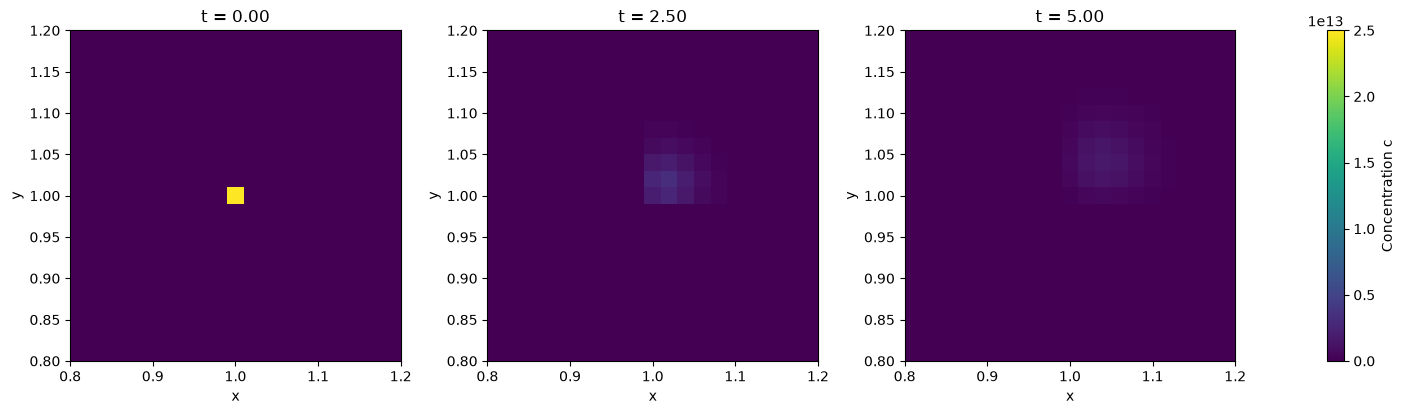

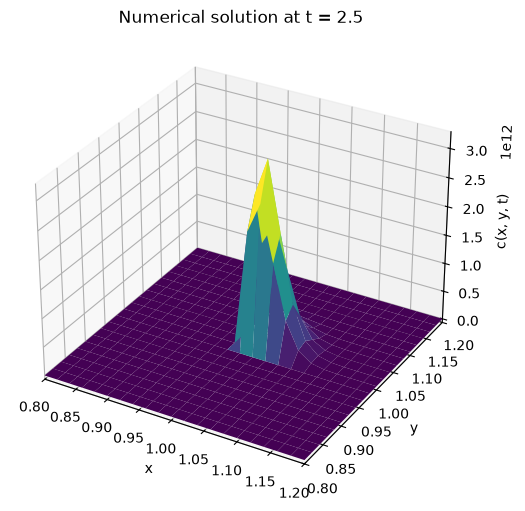

Total comcentration at t=0


In [107]:
test()